In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
## setting the number of rows to be displayed as 50
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 50)

In [3]:
df = pd.read_csv("../data/raw/creditcard.csv")
df.shape

(284807, 31)

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Data Checks: Missing values and duplicates

In [5]:
# check for missing values
missing_counts = df.isna().sum()
print(f'Columns with missing values: {missing_counts.sum()}')

# check for the data types of the columns
df.info()


Columns with missing values: 0
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  flo

In [6]:
# check for duplicates
duplicates = df.duplicated(keep='first')
print(f'Extra duplicated rows - to be dropped: {duplicates.sum()}')
print(f'Extra duplicates by Class \n{df.loc[duplicates, 'Class'].value_counts()}')
print(f'All rows which are duplicated {df.duplicated(keep=False).sum()}')

Extra duplicated rows - to be dropped: 1081
Extra duplicates by Class 
Class
0    1062
1      19
Name: count, dtype: int64
All rows which are duplicated 1854


### Findings
* We don't have any missing values. So no need to inlude an Imputer, but we should also be mindful of the users where the null values can come and an imputer might be requred
* Overall we have 1081 (class 0: 1062 and class 1: 19) duplicate rows which need to be dropped and keep only the unique ones before splitting the data into train and test to prevent data leakage.

## Target Distribution

            count    percent
Legit (0)  284315  99.827251
Fraud (1)     492   0.172749


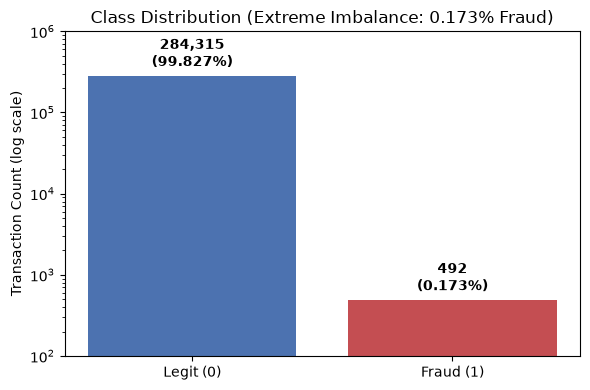

In [7]:
counts = df.Class.value_counts().sort_index()
pcts = df.Class.value_counts(normalize=True).sort_index() * 100

summary = pd.DataFrame({"count": counts, "percent": pcts})
summary.index = ['Legit (0)', 'Fraud (1)']

print(summary)

# plotting the distribution
ffig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(summary.index, summary["count"], color=["#4C72B0", "#C44E52"])
ax.set_yscale("log")
ax.set_ylabel("Transaction Count (log scale)")
ax.set_title("Class Distribution (Extreme Imbalance: 0.173% Fraud)")
for bar, cnt, pct in zip(bars, summary["count"], summary["percent"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        cnt * 1.15,
        f"{cnt:,}\n({pct:.3f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )
ax.set_ylim(100, 1_000_000)
plt.tight_layout()
plt.show()

### Findings:
* Only 492 (0.17%) are fraud. So there is severe calss imbalance and we can't use Accuracy as a metric. Also, we will have to resort to precision/ recall/ F1-score as our evaluation metrics.

## Amount: Skewness, Zero-Value Transactions & Fraud Behavior

                0.00  0.25   0.50    0.75    0.90     0.99      1.00
Legitimate (0)   0.0  5.65  22.00   77.05  202.72  1016.97  25691.16
Fraud (1)        0.0  1.00   9.25  105.89  346.75  1357.43   2125.87
Zero-amount transactions by Class: {0: 1798, 1: 27}
Raw Amount skewness:   16.98
log1p(Amount) skewness: 0.16


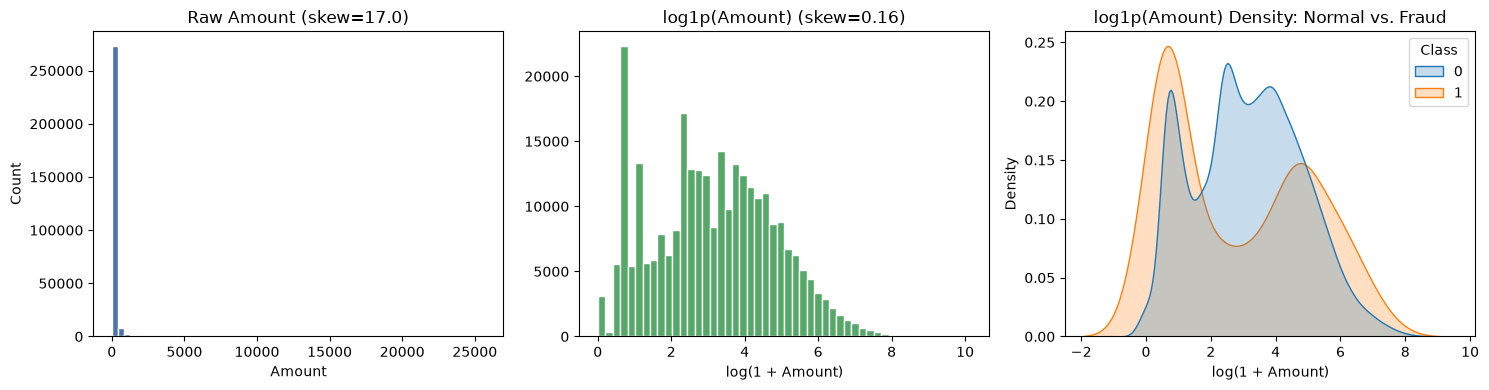

In [8]:
amt_quantiles = df.groupby("Class")["Amount"].quantile([0.0, 0.25, 0.5, 0.75, 0.9, 0.99, 1.0]).unstack()
amt_quantiles.index = ["Legitimate (0)", "Fraud (1)"]
print(amt_quantiles.round(2))

print("Zero-amount transactions by Class:", df.loc[df["Amount"] == 0, "Class"].value_counts().to_dict())
print(f"Raw Amount skewness:   {df['Amount'].skew():.2f}")
print(f"log1p(Amount) skewness: {np.log1p(df['Amount']).skew():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Raw Amount (heavily right-skewed)
axes[0].hist(df["Amount"], bins=60, color="#4C72B0", edgecolor="white")
axes[0].set_title(f"Raw Amount (skew={df['Amount'].skew():.1f})")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Count")

# 2. log1p(Amount)
log_amt = np.log1p(df["Amount"])
axes[1].hist(log_amt, bins=50, color="#55A868", edgecolor="white")
axes[1].set_title(f"log1p(Amount) (skew={log_amt.skew():.2f})")
axes[1].set_xlabel("log(1 + Amount)")

# 3. log1p(Amount) density by Class (sample normal class for fast KDE, keep all frauds)
amt_plot_df = pd.concat([
    df[df["Class"] == 0].sample(n=15_000, random_state=42),
    df[df["Class"] == 1],
], ignore_index=True)
amt_plot_df["log_amount"] = np.log1p(amt_plot_df["Amount"])
sns.kdeplot(data=amt_plot_df, x="log_amount", hue="Class", common_norm=False, fill=True, ax=axes[2])
axes[2].set_title("log1p(Amount) Density: Normal vs. Fraud")
axes[2].set_xlabel("log(1 + Amount)")

plt.tight_layout()
plt.show()

### Findings:
* The conception that higher valued transactions are Fraud is not true here. Fraudulent transactions has a mean of 9.25 compared to the 22 for legit transactions.
* Also, Fraud transactions has higher 75th and 90th percentile values.
* Scaling Choice: If we use StandardScaler directly, since the skewness of raw Amount column is high (~17), the values will be minimised. So, a better option could be RobustScaler or log1p + StandardScaler.

## Time

In [9]:
min_time, max_time = df.Time.agg(['min', 'max']).values
print(f'Time period the data: {min_time//3600} hours to {max_time//3600} hours')

Time period the data: 0.0 hours to 47.0 hours


#### We can see that the data is spread across 48 hours, so lets examine if we can find any pattern for the fraud transactions

       total_tx  fraud_count  fraud_rate
day                                     
Day 1    144786          281    0.001941
Day 2    140021          211    0.001507


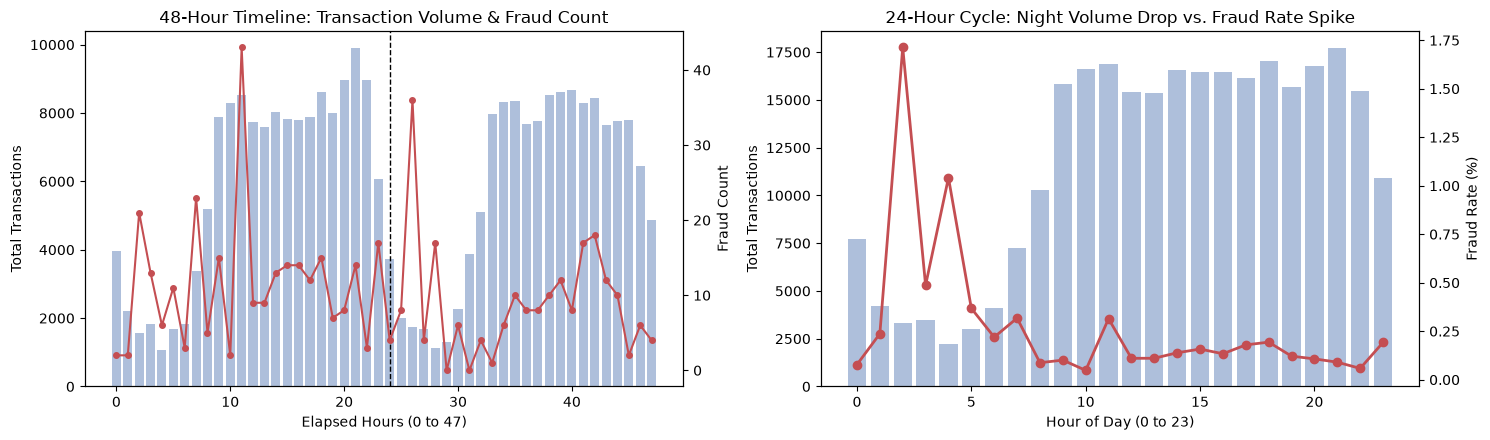

In [10]:
time_df = df[["Time", "Class"]].copy()
time_df["hour_48"] = (time_df["Time"] // 3600).astype(int)
time_df["hour_24"] = time_df["hour_48"] % 24
time_df["day"] = np.where(time_df["Time"] < 86400, "Day 1", "Day 2")

print(time_df.groupby("day")["Class"].agg(total_tx="count", fraud_count="sum", fraud_rate="mean"))

hourly_48 = time_df.groupby("hour_48")["Class"].agg(total_tx="count", fraud_count="sum", fraud_rate="mean").reset_index()
hourly_24 = time_df.groupby("hour_24")["Class"].agg(total_tx="count", fraud_count="sum", fraud_rate="mean").reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# 48h timeline (Day 1 vs Day 2)
ax = axes[0]
ax.bar(hourly_48["hour_48"], hourly_48["total_tx"], color="#4C72B0", alpha=0.45, label="Total Tx")
ax.axvline(24, color="black", linestyle="--", linewidth=1, label="Day 1 -> Day 2")
ax.set_xlabel("Elapsed Hours (0 to 47)")
ax.set_ylabel("Total Transactions")
ax.set_title("48-Hour Timeline: Transaction Volume & Fraud Count")
ax_r = ax.twinx()
ax_r.plot(hourly_48["hour_48"], hourly_48["fraud_count"], color="#C44E52", marker="o", markersize=4, label="Fraud Count")
ax_r.set_ylabel("Fraud Count")

# 24h folded cycle (Volume vs Fraud Rate)
ax2 = axes[1]
ax2.bar(hourly_24["hour_24"], hourly_24["total_tx"], color="#4C72B0", alpha=0.45)
ax2.set_xlabel("Hour of Day (0 to 23)")
ax2.set_ylabel("Total Transactions")
ax2.set_title("24-Hour Cycle: Night Volume Drop vs. Fraud Rate Spike")
ax2_r = ax2.twinx()
ax2_r.plot(hourly_24["hour_24"], hourly_24["fraud_rate"] * 100, color="#C44E52", marker="o", linewidth=2)
ax2_r.set_ylabel("Fraud Rate (%)")

plt.tight_layout()
plt.show()

### Findings:
* We can clearly see that the fraud transactions are more prominent at Night time (hours 0-6).
* Also, this gives us some idea about how to split the data for training and testing. We can't simply split the data using stratification but we should split it chronologically to verify if model generalises well.

## V1-V28

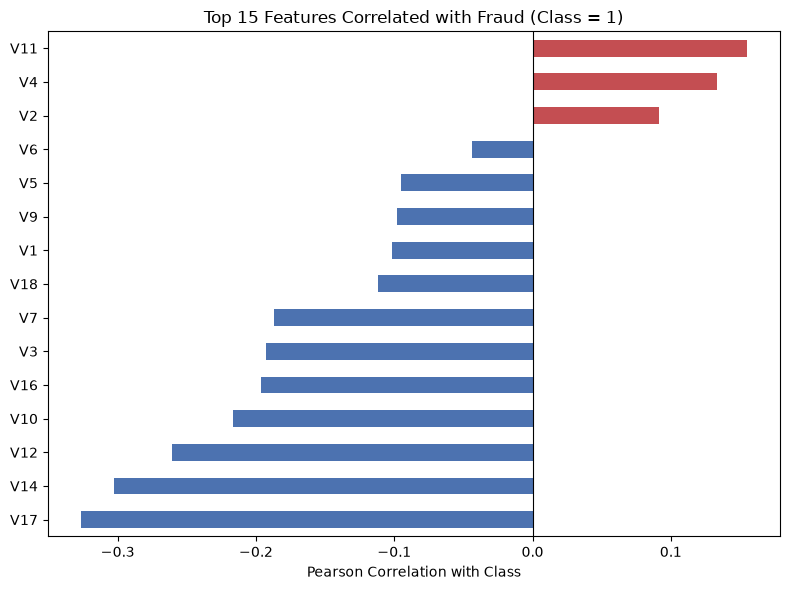

In [11]:
v_cols = [f"V{i}" for i in range(1, 29)]
corrs = df[v_cols + ["Amount", "Class"]].corr()["Class"].drop("Class")
corrs_sorted = corrs.reindex(corrs.abs().sort_values(ascending=False).index)

fig, ax = plt.subplots(figsize=(8, 6))
top_15 = corrs_sorted.head(15).sort_values()
colors = ["#C44E52" if v > 0 else "#4C72B0" for v in top_15.values]
top_15.plot(kind="barh", color=colors, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Top 15 Features Correlated with Fraud (Class = 1)")
ax.set_xlabel("Pearson Correlation with Class")
plt.tight_layout()
plt.show()

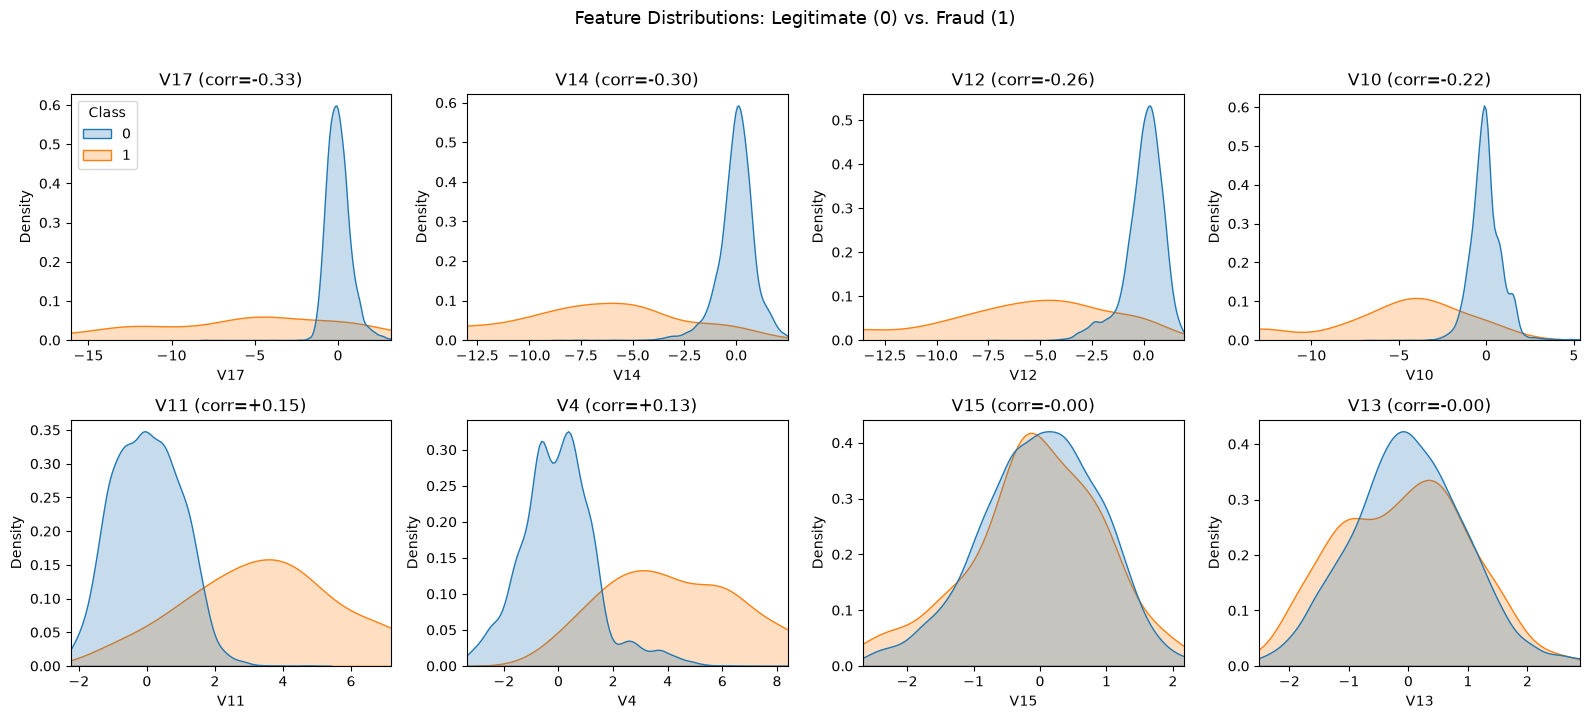

In [12]:
# Compare full distributions not just medians for top 6 separating features + 2 weak features (V13 and V15)
inspect_cols = ["V17", "V14", "V12", "V10", "V11", "V4", "V15", "V13"]
# Use a balanced subsample of legit rows just for fast KDE visualization
legit_sample = df[df["Class"] == 0].sample(n=10_000, random_state=42)
fraud_rows = df[df["Class"] == 1]
plot_df = pd.concat([legit_sample, fraud_rows], ignore_index=True)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, inspect_cols):
    sns.kdeplot(data=plot_df, x=col, hue="Class", common_norm=False, fill=True, ax=ax, legend=(col == "V17"))
    ax.set_title(f"{col} (corr={corrs[col]:+.2f})")
    ax.set_xlim(plot_df[col].quantile(0.005), plot_df[col].quantile(0.995))

plt.suptitle("Feature Distributions: Legitimate (0) vs. Fraud (1)", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

### Findings:
* Features V17, V14, V12, V10, V11, V4 show significant distribution shifts between normal and fraudulant transactions.
* Also, since these features came out good, may be we can monitor them for data drift alert as they would impact the final model significantly.